# Second Task :  Unemployment Analysis with Python

**- Target :** clean, explore, and visualize unemployment rate data, measure the **impact of Covid-19**, spot trends or seasonal effects, and then draw useful insights for economic or social policies.

**Data:** *Unemployment in India.csv* & *Unemployment_Rate_upto_11_2020.csv*.

## Fist Step : import librairies

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', 30)

LOCKDOWN = pd.Timestamp('2020-03-25')  # Approximate start of COVID-19 lockdowns

## Step 2 : Load data

In [6]:
def clean(path) :
    df = pd.read_csv(path, encoding='utf-8-sig')
    df.columns = df.columns.str.strip()  # Remove leading/trailing whitespace from column names
    df = df.dropna(how='all')
    for col in df.select_dtypes(include=["object", "string"]).columns:
        df[col] = df[col].str.strip()  # Remove leading/trailing whitespace from string columns
    df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")
    df = df.rename(columns={
        "Estimated Unemployment Rate (%)": "Unemployment",
        "Estimated Employed": "Employed",
        "Estimated Labour Participation Rate (%)": "Participation", 
    })
    return df.drop_duplicates().sort_values(["Region", "Date"]).reset_index(drop=True)

a = clean("Unemployment in India.csv")
b = clean("Unemployment_Rate_upto_11_2020.csv")

print("File A :", a.shape, "|", a["Date"].min().date(), '->', a["Date"].max().date(), "|", a["Region"].nunique(), "regions")
print("File B :", b.shape, "|", b["Date"].min().date(), '->', b["Date"].max().date(), "|", b["Region"].nunique(), "regions")
print("\n Missing values in File A:\n", a.isnull().sum(), "| B:", b.isnull().sum())
display(a.head(3))
display(b.head(3))

File A : (740, 7) | 2019-05-31 -> 2020-06-30 | 28 regions
File B : (267, 9) | 2020-01-31 -> 2020-10-31 | 27 regions

 Missing values in File A:
 Region           0
Date             0
Frequency        0
Unemployment     0
Employed         0
Participation    0
Area             0
dtype: int64 | B: Region           0
Date             0
Frequency        0
Unemployment     0
Employed         0
Participation    0
Region.1         0
longitude        0
latitude         0
dtype: int64


,Region,Date,Frequency,Unemployment,Employed,Participation,Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-05-31,Monthly,6.09,4788661.0,37.45,Urban
2,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural


,Region,Date,Frequency,Unemployment,Employed,Participation,Region.1,longitude,latitude
0,Andhra Pradesh,2020-01-31,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,2020-02-29,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,2020-03-31,M,5.79,15881197,39.18,South,15.9129,79.74


## Step 3 : Explore Data

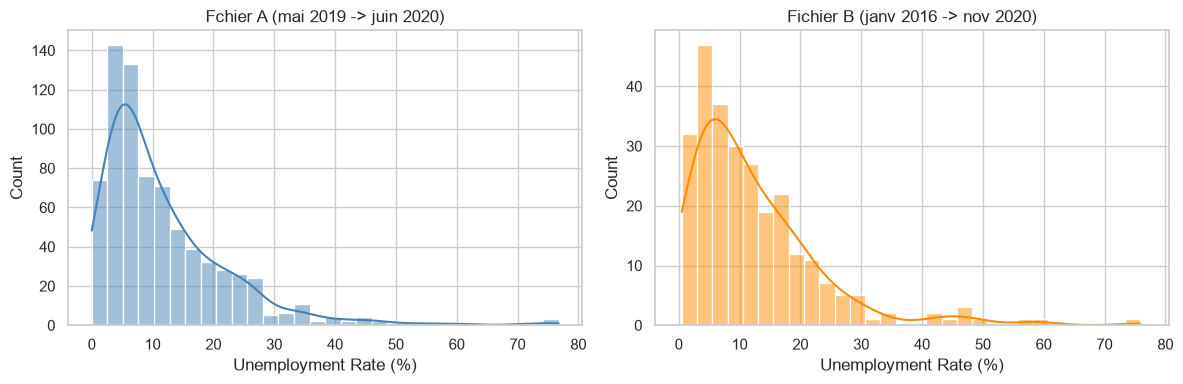

Maximum value A: 76.74 | B: 75.85


,Unemployment,Employed,Participation
count,740.00,740.00,740.00
mean,11.79,7204460.03,42.63
std,10.72,8087988.43,8.11
min,0.00,49420.00,13.33
25%,4.66,1190404.50,38.06
50%,8.35,4744178.50,41.16
75%,15.89,11275489.50,45.50
max,76.74,45777509.00,72.57


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
sns.histplot(a["Unemployment"], bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Fchier A (mai 2019 -> juin 2020)")
sns.histplot(b["Unemployment"], bins=30, kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("Fichier B (janv 2016 -> nov 2020)")
for ax in axes:
    ax.set_xlabel("Unemployment Rate (%)")
plt.tight_layout()
plt.show()

print("Maximum value A:", a["Unemployment"].max(), "| B:", b["Unemployment"].max())
a[["Unemployment", "Employed", "Participation"]].describe().round(2)

The distribution has a long right tail. These very high values are not errors: they are the lockdown months (April-May 2020). We **keep** them, because they *are* the phenomenon we are studying.

## Step 4 : The situation before covid (File A)

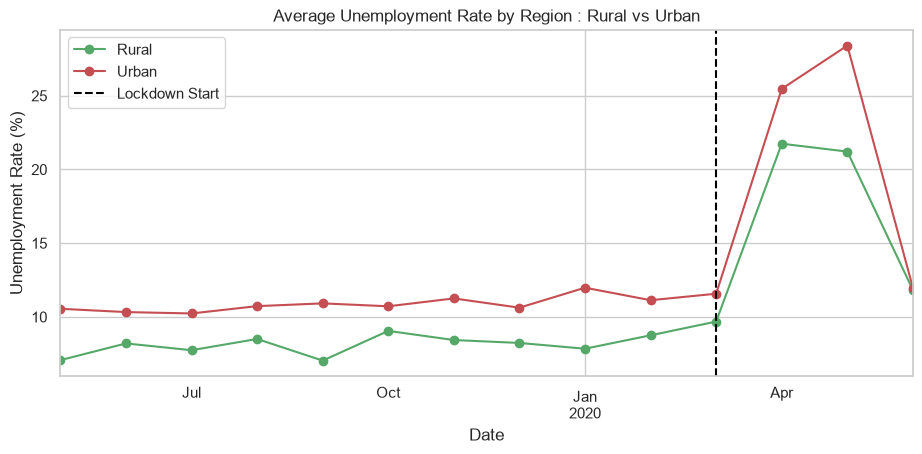

Average rate Before Covid (mai 2019 -> fév 2020)
Area
Rural     8.09
Urban    10.84


In [12]:
ru = a.groupby(["Date", "Area"])["Unemployment"].mean().unstack()

fig, ax = plt.subplots(figsize=(11, 4.5))
ru.plot(ax=ax, marker="o", color=["#55a868", "#c44e52"])
ax.axvline(LOCKDOWN, color="black", linestyle="--", label="Lockdown Start")
ax.set_title("Average Unemployment Rate by Region : Rural vs Urban")
ax.set_ylabel("Unemployment Rate (%)")
ax.legend()
plt.show()

pre = a[a["Date"] < "2020-03-01"]
print("Average rate Before Covid (mai 2019 -> fév 2020)")
print(pre.groupby("Area")["Unemployment"].mean().round(2).to_string())

Before Covid, unemployment was structurally **higher in cities than in the countryside** (around 10-11% versus 7-9%). At the time of the lockdown, both areas shot up.

## Step 5 : The full arc of the crisis (File B): shock and recovery

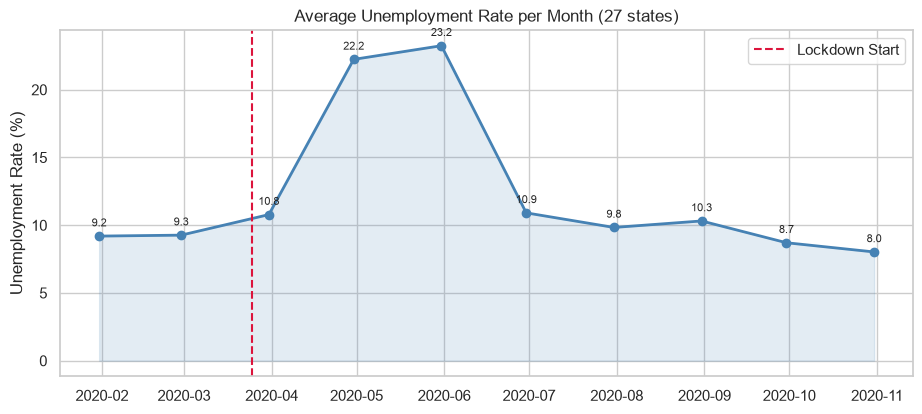

In [14]:
nat = b.groupby("Date")["Unemployment"].mean()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(nat.index, nat.values, marker='o', color="steelblue", linewidth=2)
ax.axvline(LOCKDOWN, color='crimson', linestyle='--', label='Lockdown Start')
ax.fill_between(nat.index, nat.values, color='steelblue', alpha=0.15)
for d, v in nat.items():
    ax.annotate(f"{v:.1f}", (d, v), textcoords="offset points", xytext=(0, 7), ha='center', fontsize=8)
ax.set_title("Average Unemployment Rate per Month (27 states)")
ax.set_ylabel("Unemployment Rate (%)")
ax.legend()
plt.show()

In [16]:
before = b[b["Date"] < "2020-03-01"]["Unemployment"].mean()
choc = b[(b["Date"] >= "2020-04-01") & (b["Date"] <= "2020-05-31")]["Unemployment"].mean()
last = b[b["Date"] == b["Date"].max()]["Unemployment"].mean()
pic_mois = nat.idxmax()

print(f"Before Covid (jan-feb 2020)      : {before:.1f} %")
print(f"During the choc (avril-mai)     : {choc:.1f} %  (x{choc / before:.1f})")
print(f"last month ({b['Date'].max():%B %Y})      : {last:.1f} %")
print(f"National Pic : {pic_mois:%B %Y} avec {nat.max():.1f} %")
print(f"\nThe rate has returned to {last / before * 100:.0f}% of its pre-crisis level.")

Before Covid (jan-feb 2020)      : 9.2 %
During the choc (avril-mai)     : 22.7 %  (x2.5)
last month (October 2020)      : 8.0 %
National Pic : May 2020 avec 23.2 %

The rate has returned to 87% of its pre-crisis level.


Unemployment more than **doubled** as early as April, then collapsed as of June with the gradual lifting of the lockdown. In October, it was even **below** the January-February level (8.0% versus 9.2%). Caution: this does not mean that everything is going well (see step 8, labor market participation).

## Step 6 : Which states were the most affected?

,Before,choc (avr-mai),October,Increase,Retu
Region,,,,,
Puducherry,1.2,67.0,6.2,65.8,60.8
Jharkhand,11.2,53.2,11.8,41.9,41.4
Tamil Nadu,1.8,41.5,2.2,39.7,39.3
Bihar,10.4,46.3,9.8,35.8,36.5
Karnataka,3.2,24.9,1.6,21.7,23.3
Odisha,2.5,17.6,2.2,15.1,15.4
Maharashtra,4.8,18.2,4.1,13.4,14.1
Andhra Pradesh,5.7,19.0,6.6,13.3,12.4
Haryana,23.1,36.1,27.3,13.1,8.8


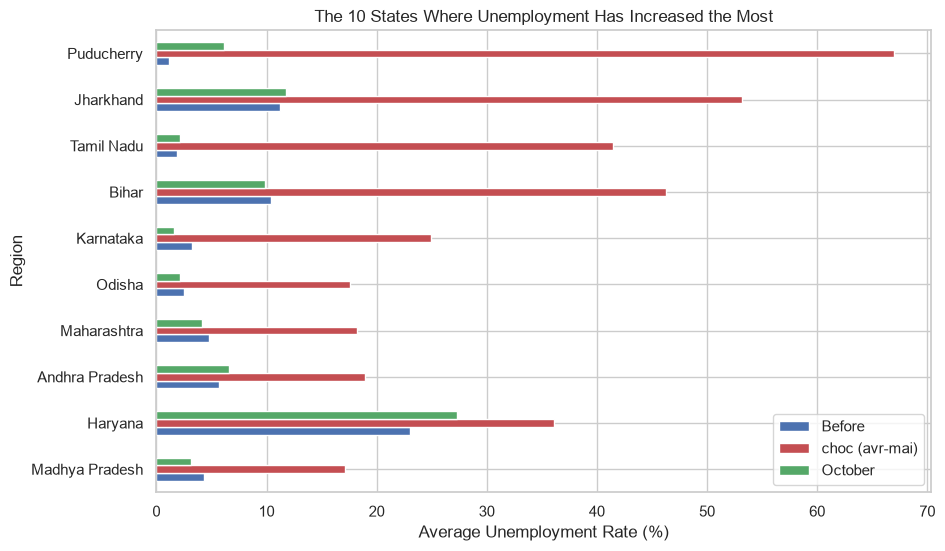

In [21]:
def mean_period(df, start, end):
    m = (df["Date"] >= start) & (df["Date"] <= end)
    return df[m].groupby("Region")["Unemployment"].mean()

impact = pd.DataFrame({
    "Before" : mean_period(b, "2020-01-01", "2020-02-29"),
    "choc (avr-mai)" : mean_period(b, "2020-04-01", "2020-05-31"),
    "October" : mean_period(b, "2020-10-01", "2020-10-31"),
})
impact["Increase"] = impact["choc (avr-mai)"] - impact["Before"]
impact["Retu"] = impact["choc (avr-mai)"] - impact["October"]
impact = impact.sort_values("Increase", ascending=False)
display(impact.head(10).round(1))

top = impact.head(10).iloc[::-1]
top[["Before", "choc (avr-mai)", "October"]].plot(kind="barh", figsize=(10, 6),
                                                 color=["#4c72b0", "#c44e52", "#55a868"])
plt.title("The 10 States Where Unemployment Has Increased the Most")
plt.xlabel("Average Unemployment Rate (%)")
plt.show()

In [22]:
print("States where unemployment in October remains HIGHER than before the crisis:")
rest = impact[impact["October"] > impact["Before"]].sort_values("October", ascending=False)
print(rest[["Before", "October"]].round(1).head(8).to_string())

States where unemployment in October remains HIGHER than before the crisis:
                Before  October
Region                         
Haryana           23.1     27.3
Rajasthan         13.1     24.2
Jharkhand         11.2     11.8
Goa                5.9     11.5
West Bengal        5.9     10.0
Uttarakhand        5.2      9.2
Andhra Pradesh     5.7      6.6
Puducherry         1.2      6.2


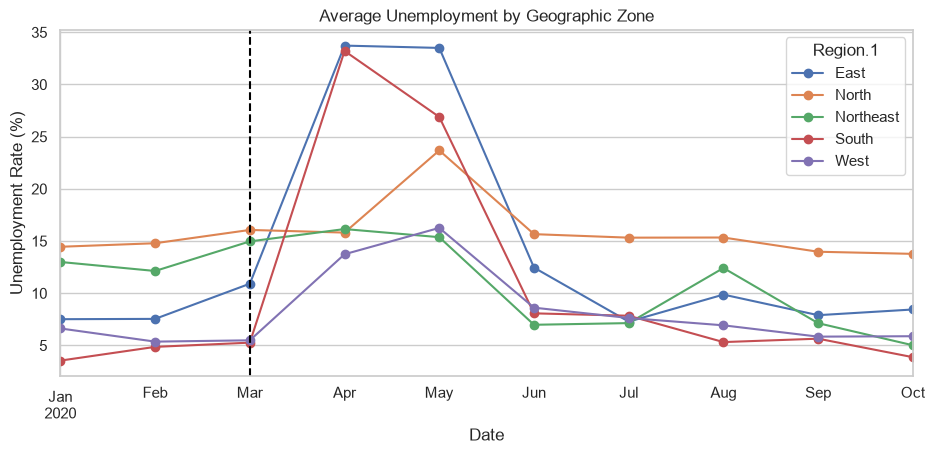

Average Rate in April-May 2020 by Zone:
Region.1
East         33.6
South        30.0
North        20.0
Northeast    15.8
West         15.0


In [26]:
zone = b.groupby(["Date", "Region.1"])["Unemployment"].mean().unstack()

fig, ax = plt.subplots(figsize=(11, 4.5))
zone.plot(ax=ax, marker="o")
ax.axvline(LOCKDOWN, color="black", linestyle="--")
ax.set_title("Average Unemployment by Geographic Zone")
ax.set_ylabel("Unemployment Rate (%)")
plt.show()

print("Average Rate in April-May 2020 by Zone:")
print(b[(b["Date"] >= "2020-04-01") & (b["Date"] <= "2020-05-31")].groupby("Region.1")["Unemployment"].mean().sort_values(ascending=False).round(1).to_string())

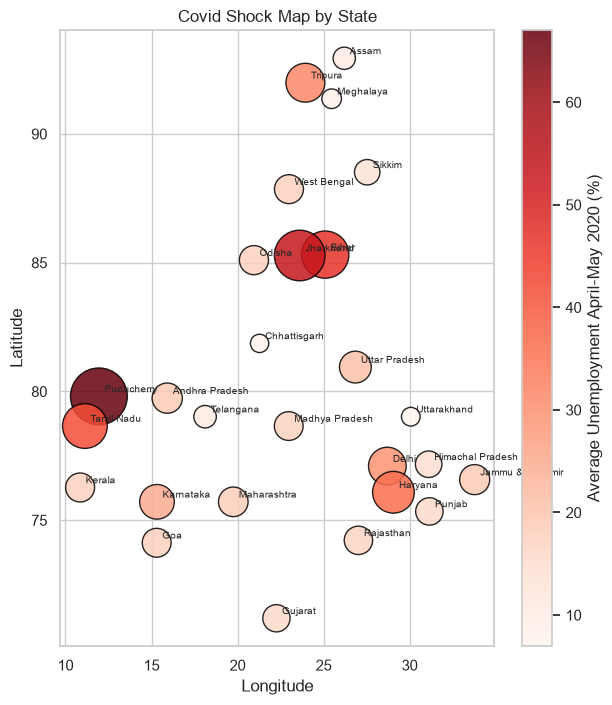

In [29]:
choc_etat = b[(b["Date"] >= "2020-04-01") & (b["Date"] <= "2020-05-31")].groupby("Region").agg(
    Unemployment=("Unemployment", "mean"), lat=("latitude", "first"), lon=("longitude", "first"))

fig, ax = plt.subplots(figsize=(7, 8))
sc = ax.scatter(choc_etat["lon"], choc_etat["lat"], s=choc_etat["Unemployment"] * 25,
                c=choc_etat["Unemployment"], cmap="Reds", edgecolor="black", alpha=0.85)
for name, r in choc_etat.iterrows():
    ax.annotate(name, (r["lon"], r["lat"]), fontsize=7, xytext=(4, 3), textcoords="offset points")
plt.colorbar(sc, label="Average Unemployment April-May 2020 (%)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Covid Shock Map by State")
plt.show()

## Step 8 : Unemployment, Employment, and Labor Market Participation
When unemployment rises, do the number of people who are employed (`Employed`) and the participation rate decrease? **Participation** is important: if people give up looking for work, they are no longer counted in the unemployment calculation.

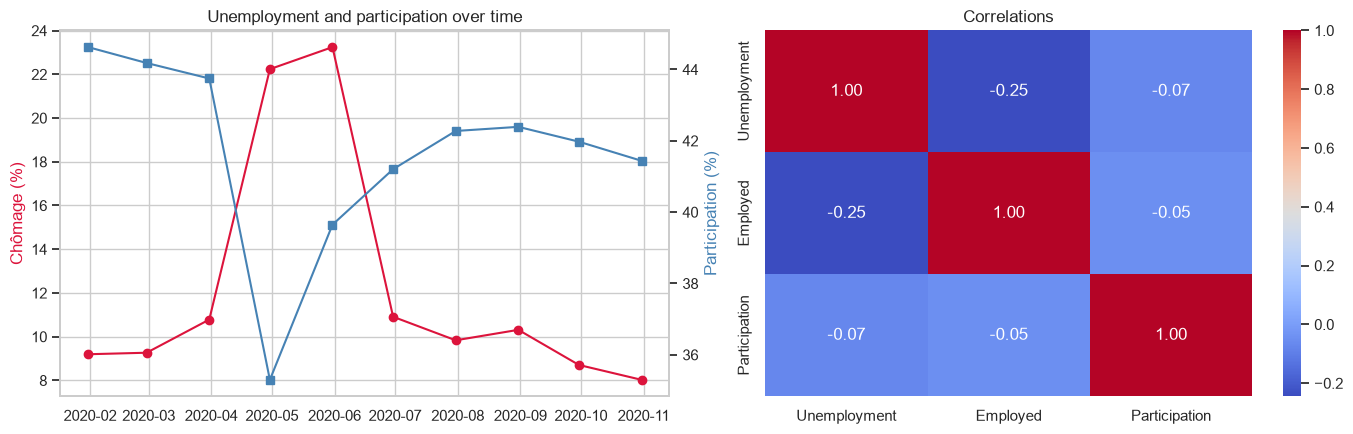

Average Participation :
Date
2020-01-31    44.6
2020-02-29    44.2
2020-03-31    43.7
2020-04-30    35.3
2020-05-31    39.6
2020-06-30    41.2
2020-07-31    42.3
2020-08-31    42.4
2020-09-30    42.0
2020-10-31    41.4


In [ ]:
m = b.groupby("Date")[["Unemployment", "Employed", "Participation"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ax1 = axes[0]
ax1.plot(m.index, m["Unemployment"], color="crimson", marker="o")
ax1.set_ylabel("Unemployment (%)", color="crimson")
ax2 = ax1.twinx()
ax2.plot(m.index, m["Participation"], color="steelblue", marker="s")
ax2.set_ylabel("Participation (%)", color="steelblue")
ax2.grid(False)
ax1.set_title("Unemployment and participation over time")

sns.heatmap(b[["Unemployment", "Employed", "Participation"]].corr(), annot=True, cmap="coolwarm", fmt=".2f", ax=axes[1])
axes[1].set_title("Correlations")
plt.tight_layout()
plt.show()

print("Average Participation :")
print(m["Participation"].round(1).to_string())

## Step 9 : Seasonal trends: what can be said? 
Before Covid, file A only covers **10 months** (May 2019 → Feb 2020), so not a full annual cycle. We can look at the 2019 trend, but **we cannot conclude to a reliable seasonality**.

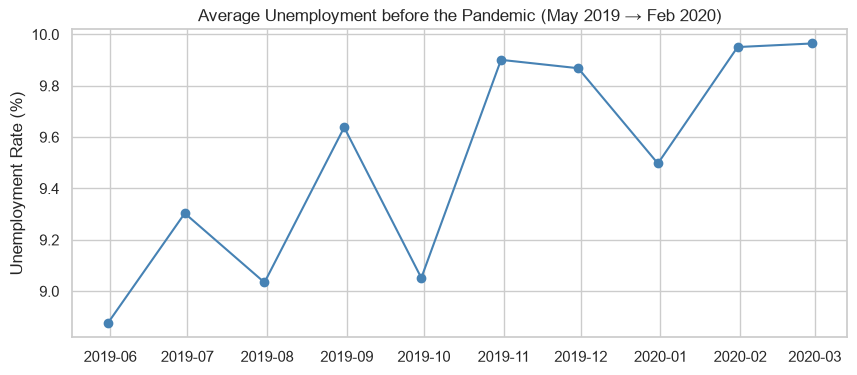

Between the minimum (8.9 %) and the maximum (10.0 %), the range is 1.1 percentage point(s): relatively small compared to the pandemic shock.


In [33]:
pre_nat = a[a["Date"] < "2020-03-01"].groupby("Date")["Unemployment"].mean()

plt.figure(figsize=(10, 4))
plt.plot(pre_nat.index, pre_nat.values, marker="o", color="steelblue")
plt.title("Average Unemployment before the Pandemic (May 2019 → Feb 2020)")
plt.ylabel("Unemployment Rate (%)")
plt.show()

print(f"Between the minimum ({pre_nat.min():.1f} %) and the maximum ({pre_nat.max():.1f} %), the range is {pre_nat.max() - pre_nat.min():.1f} percentage point(s): relatively small compared to the pandemic shock.")

# Conclusion and Recommendations

**What the data shows**
- **A massive, short-lived shock:** Average unemployment rose from 9.2% (Jan–Feb) to approximately 23% in April–May 2020 (a 2.5-fold increase), before falling back as early as June; by October, it stood at 8.0%—below its pre-crisis level.
- **However, the recovery is incomplete:** Labor force participation dropped from 44.6% to 35.3% in April and had only recovered to 41.4% by October. A portion of the population has therefore left the labor market, which lowers the unemployment rate even though these individuals have not found new employment.
- **Urban areas were hit harder** than rural areas: Urban unemployment was already higher before the crisis and experienced the sharpest increase.
- **Significant disparities between states:** Puducherry (rising from 1.2% to 67%), Jharkhand (53%), Tamil Nadu (41%), and Bihar (46%) were the most severely affected in April–May; in Haryana, where rates were already very high before the crisis, unemployment remained at 27% in October. As of October, 10 out of 27 states remained above their pre-crisis levels (stages 6 and 7).
- **No reliable conclusions regarding seasonality:** The pre-crisis period is too short to draw such inferences.

**Directions for economic and social policy**
1. **Targeted assistance** for the states and areas most severely affected, rather than uniform support.
2. **Protection for urban and informal-sector workers** (e.g., income replacement, support for the recovery of small businesses).
3. **Training and retraining programs** for those unable to find new employment. 
4. **Monitor labor force participation**, not just the unemployment rate: a decline in unemployment may mask individuals who have stopped looking for work.

**Limitations of the analysis**
- **Simple** averages across states, unweighted by population (a small state carries as much weight as a large one).
- The two datasets do not have identical coverage (28 regions versus 27; Chandigarh is absent from dataset B); the analysis compares orders of magnitude rather than precise figures down to the hundredth decimal place.
- Data are **estimates** and cover a short period: the analysis describes an exceptional event rather than predicting the future.